# Working with SDF files

In [24]:
from rdkit import Chem
mols = Chem.SDMolSupplier('sdf_dataset.sdf', sanitize=True)
for mol in mols:
    print(mol)

None


[14:04:55] Explicit valence for atom # 2 N, 4, is greater than permitted
[14:04:55] ERROR: Could not sanitize molecule ending on line 60
[14:04:55] ERROR: Explicit valence for atom # 2 N, 4, is greater than permitted


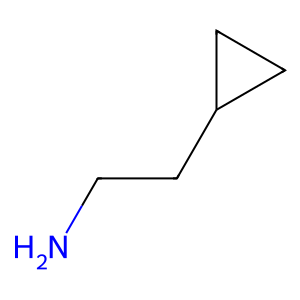

In [30]:
from IPython.display import SVG, display
from rdkit.Chem.Draw import rdMolDraw2D


def render_mol_svg(molecule, width=300, height=300):
    drawer = rdMolDraw2D.MolDraw2DSVG(width, height)
    rdMolDraw2D.PrepareAndDrawMolecule(drawer, molecule)
    drawer.FinishDrawing()
    return SVG(drawer.GetDrawingText())

render_mol_svg(mols[1])

# Working with Smiles format file

Number of molecules: 5


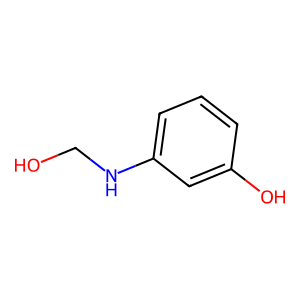

In [49]:
mols = Chem.SmilesMolSupplier('./smi_dataset/smi_dataset.smi', sanitize=False)
molsCSV = Chem.SmilesMolSupplier('./smi_dataset/smi_dataset.csv', delimiter=',')
print(f"Number of molecules: {len(mols)}")
for mol in mols:
    print(mol)  

render_mol_svg(mols[0])

creating mol from simles

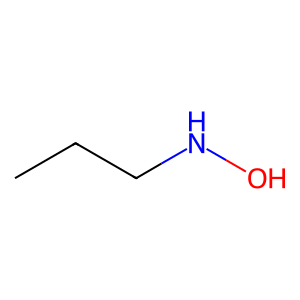

In [50]:
mol = Chem.MolFromSmiles('CCCNO')
render_mol_svg(mol)

In [56]:
print(f"Number of atoms in the molecule: {mol.GetNumAtoms()}")
print(f"Number of bonds in the molecule: {mol.GetNumBonds()}")

for atom in mol.GetAtoms():
    print(f"Atom index: {atom.GetIdx()}, Atom symbol: {atom.GetSymbol()}, Atom degree: {atom.GetDegree()}, Atom charge: {atom.GetFormalCharge()}")


for bond in mol.GetBonds():
    print(f"Bond index: {bond.GetIdx()}, Bond type: {bond.GetBondType()}")

Number of atoms in the molecule: 5
Number of bonds in the molecule: 4
Atom index: 0, Atom symbol: C, Atom degree: 1, Atom charge: 0
Atom index: 1, Atom symbol: C, Atom degree: 2, Atom charge: 0
Atom index: 2, Atom symbol: C, Atom degree: 2, Atom charge: 0
Atom index: 3, Atom symbol: N, Atom degree: 2, Atom charge: 0
Atom index: 4, Atom symbol: O, Atom degree: 1, Atom charge: 0
Bond index: 0, Bond type: SINGLE
Bond index: 1, Bond type: SINGLE
Bond index: 2, Bond type: SINGLE
Bond index: 3, Bond type: SINGLE


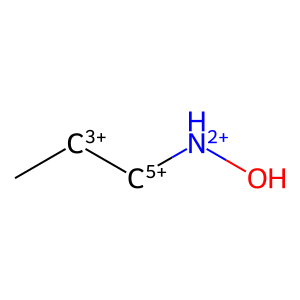

In [66]:
atom1 = mol.GetAtomWithIdx(1)
atom1.SetFormalCharge(3)
atom2 = mol.GetAtomWithIdx(3)
atom2.SetFormalCharge(2)
render_mol_svg(mol)

2.0
True


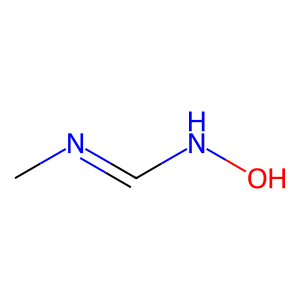

In [75]:
mol = Chem.MolFromSmiles('CN=CNO')
bond1 = mol.GetBondWithIdx(1)
bond1TypeNum = bond1.GetBondTypeAsDouble()
print(bond1TypeNum)
print(bond1TypeNum == 2)
render_mol_svg(mol)

Bond index: 0, Bond type: SINGLE
Bond index: 1, Bond type: DOUBLE
Bond index: 2, Bond type: SINGLE
Bond index: 3, Bond type: SINGLE


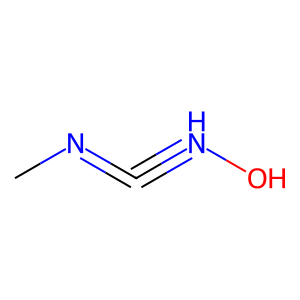

In [76]:
for bond in mol.GetBonds():
    print(f"Bond index: {bond.GetIdx()}, Bond type: {bond.GetBondType()}")

mol.GetBondWithIdx(2).SetBondType(Chem.rdchem.BondType.TRIPLE)
render_mol_svg(mol)

Number of conformers: 0


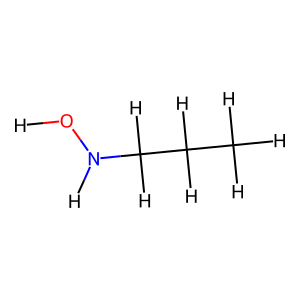

In [83]:
# Number of Confromers
mol = Chem.MolFromSmiles('CCCNO')
mol = Chem.AddHs(mol) # Add hydrogen atoms
num_conformers = mol.GetNumConformers()
print(f"Number of conformers: {num_conformers}")
render_mol_svg(mol)

In [87]:
# Generate 3D coordinates for the molecule
from rdkit.Chem import AllChem
AllChem.EmbedMolecule(mol)
num_conformers = mol.GetNumConformers()
print(f"Number of conformers: {num_conformers}")
mol.GetConformers()[0].GetPositions()

Number of conformers: 1


array([[ 1.43380375,  0.32844419, -0.41914959],
       [ 0.73547614, -0.82340211,  0.21905396],
       [-0.77517317, -0.77357704,  0.1054488 ],
       [-1.32462767,  0.40566377,  0.7253962 ],
       [-0.88037164,  1.56195805,  0.19510463],
       [ 2.40157324, -0.07990242, -0.83402443],
       [ 1.73416046,  1.06340906,  0.38135933],
       [ 0.84993906,  0.84539279, -1.20418477],
       [ 1.05947579, -1.81129306, -0.15673711],
       [ 0.92198209, -0.87998596,  1.33070223],
       [-1.10645346, -0.85975353, -0.96253586],
       [-1.14376126, -1.63114946,  0.71767863],
       [-2.35269504,  0.39397024,  0.55931575],
       [-1.55332827,  2.26022548,  0.44518733]])

#### Modifying Moelcule Structure

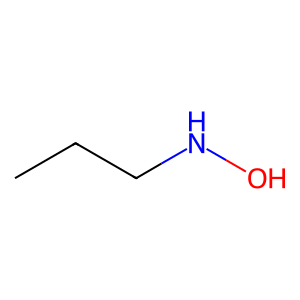

In [89]:
mol = Chem.MolFromSmiles('CCCNO')
editable_mol = Chem.RWMol(mol)
render_mol_svg(editable_mol)

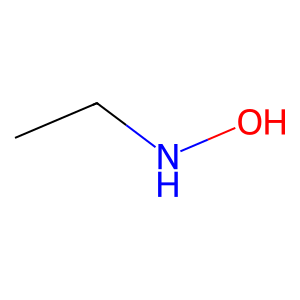

In [90]:
editable_mol.RemoveAtom(0)
render_mol_svg(editable_mol)

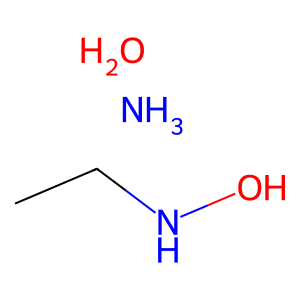

In [91]:
editable_mol.AddAtom(Chem.Atom(7))  # Add a nitrogen atom
editable_mol.AddAtom(Chem.Atom("O"))  # Add an oxygen atom
render_mol_svg(editable_mol)

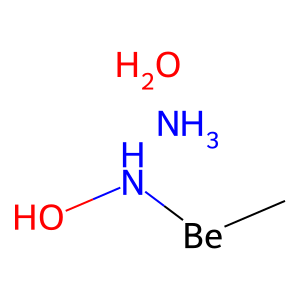

In [ ]:
editable_mol.ReplaceAtom(1, Chem.Atom(4))  # Replace atom at index 1 with an nitrogen atom
render_mol_svg(editable_mol)

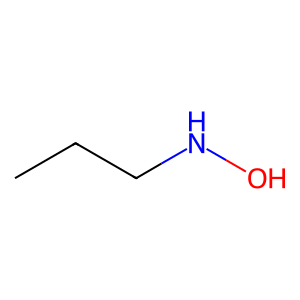

In [94]:
editable_mol = Chem.RWMol(mol)
render_mol_svg(editable_mol)

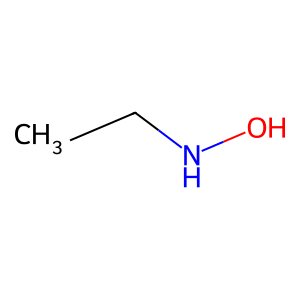

In [95]:
editable_mol.RemoveBond(0, 1)  # Remove the bond between atoms at index 0 and 1
render_mol_svg(editable_mol)

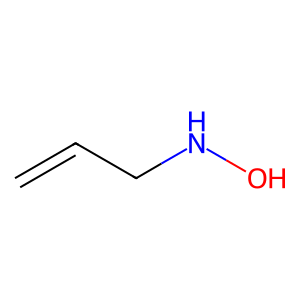

In [96]:
editable_mol.AddBond(0, 1, Chem.rdchem.BondType.DOUBLE)  # Add a double bond between atoms at index 0 and 1
render_mol_svg(editable_mol)

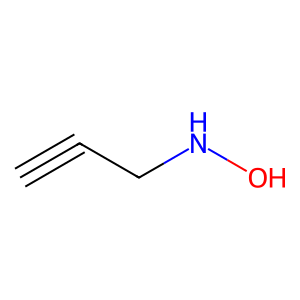

In [98]:
editable_mol.GetBondBetweenAtoms(0, 1).SetBondType(Chem.rdchem.BondType.TRIPLE)  # Change the bond type to triple
render_mol_svg(editable_mol)